# 18 · Retrieval-Augmented Generation with LangChain, evaluated with RAGAS

A language model only knows what was in its training data, and it cannot tell you where an answer came from. **RAG** keeps the knowledge in a searchable store you control and lets the model do the reasoning over what you retrieve:

```
offline:  documents ─► load ─► split into chunks ─► embed ─► vector index (FAISS)
                                                 └─────────► keyword index (BM25)
online:   question ─► dense search ──┐
                   ─► BM25 search ───┴─► RRF fusion ─► top-k chunks ─► prompt with numbered sources ─► LLM ─► answer [1][3]
```

We build it with the tools most teams use today:

| piece | tool |
|---|---|
| loading and splitting | `langchain_community` loaders, `langchain_text_splitters.RecursiveCharacterTextSplitter` |
| embeddings and LLM | `OllamaEmbeddings(nomic-embed-text)` and `ChatOllama(qwen2.5:3b)`, through `llm_edu_suite.config` |
| vector store | FAISS (`langchain_community.vectorstores.FAISS`) |
| keyword search and fusion | `BM25Retriever` and `EnsembleRetriever` (Reciprocal Rank Fusion) |
| the pipeline | LCEL (LangChain Expression Language) runnables, traced in LangSmith when a key is set |
| evaluation | our own labelled set for retrieval, and **RAGAS** for generation |

**The corpus** is the course's own documentation (`data/knowledge_base/*.md`, a snapshot of the docs: installation, glossary, CLI scripts, module reference and notebooks guide, about 190 KB). It is a realistic target: technical prose, tables, code blocks and many exact strings such as flag names and numbers.

**What you will learn:** what each component does and how to tune it, and above all how to **evaluate retrieval and generation separately**, so that when the system is wrong you know which half to fix.

## Background: retrieval-augmented generation

### Parametric and non-parametric knowledge

A language model stores what it knows **parametrically**, spread across its weights. That knowledge is frozen at training time, cannot be inspected or cited, cannot be deleted for one user, and is unreliable for rare facts: the model produces a fluent answer whether or not it actually stored the fact. A **non-parametric** memory is an external collection of documents that the system searches at query time. RAG combines the two: the retriever supplies the facts, the model supplies the language and the reasoning.

The term comes from Lewis et al. (2020, *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*), who trained a dense retriever and a seq2seq generator end to end. REALM (Guu et al., 2020) used retrieval during pre-training, and RETRO (Borgeaud et al., 2022) showed that a smaller model with retrieval over a very large database can match larger models on language modelling. What the industry calls RAG today is simpler: an off-the-shelf embedding model, a search index, and an instruction-tuned LLM that reads the retrieved passages in its prompt, with no joint training. It became the default because each piece can be swapped and updated independently, and because documents can be added or removed without touching the model.

| approach | knowledge update | citations | access control | cost to add facts |
|---|---|---|---|---|
| rely on the model | retrain | no | no | a training run |
| fine-tune on the documents | retrain | no | no | a training run; weak at injecting facts (notebook 13) |
| RAG | re-index | yes | filter at retrieval time | embed the new documents |
| long context (paste everything) | edit the prompt | possible | per request | tokens on every call |

Ovadia et al. (2024, *Fine-Tuning or Retrieval? Comparing Knowledge Injection in LLMs*) found retrieval clearly better than unsupervised fine-tuning for injecting new facts. Long-context models are a real alternative for small corpora, but every query pays for the whole context, and models use information in the middle of a long prompt less reliably (Liu et al., 2024, *Lost in the Middle*). Retrieval keeps the prompt short and focused.

### A two-stage system, and why the stages are evaluated separately

RAG is retrieve-then-read. Roughly,
$$P(\text{correct answer}) \approx P(\text{evidence retrieved}) \times P(\text{correct answer} \mid \text{evidence in context})$$
The two factors fail for different reasons and are fixed with different tools (chunking, indexing and query processing for the first; prompting, model choice and context size for the second). A single end-to-end score hides which factor is low, which is why this notebook measures retrieval with its own labelled metrics (section 10) and generation with RAGAS (section 11).

### Sparse and dense retrieval

**Sparse (lexical) retrieval** represents a text by the words it contains: a vector as long as the vocabulary, mostly zeros. TF-IDF and BM25 score a document by the query terms it contains, weighted by how rare they are. It needs no training, it is exact on identifiers, and it was hard to beat for decades. Its weakness is the **vocabulary mismatch** problem: "lower the memory of the attention cache" and "shrink the KV-cache" share almost no words.

**Dense retrieval** represents a text by a learned embedding of a few hundred dimensions, so that paraphrases land close together. DPR (Karpukhin et al., 2020, *Dense Passage Retrieval for Open-Domain Question Answering*) showed that a BERT **bi-encoder** trained on question-passage pairs beats BM25 on open-domain QA. Its weakness is the mirror image: exact strings, rare names and numbers are blurred into the general topic, and quality drops on domains unlike its training data. The BEIR benchmark (Thakur et al., 2021) found BM25 a strong baseline out of domain, with many dense models of that time falling below it.

There are three common architectures for scoring a (query, document) pair:

```
bi-encoder      query -> enc -> q          doc -> enc -> d        score = q . d          (docs pre-computed: fast, used for search)
late interaction  query -> one vector per token, doc -> one vector per token, score = sum of max-sims  (ColBERT)
cross-encoder   [query ; doc] -> one model reading both -> score                         (accurate, slow: used to rerank the top 20-100)
```

Only the bi-encoder lets you embed all documents ahead of time, which is why it is the first stage; a cross-encoder reranker (Nogueira & Cho, 2019, *Passage Re-ranking with BERT*) is the usual second stage when quality matters more than latency. ColBERT (Khattab & Zaharia, 2020) sits in between.

### Hybrid retrieval as the industry default

Because sparse and dense retrieval fail on different queries, running both and fusing the rankings is the robust default in production search stacks (Elasticsearch, OpenSearch, Weaviate, Qdrant and Vespa all ship a hybrid mode). Sections 5 and 6 cover BM25 and the fusion step.

### Key papers

- Lewis et al., 2020. *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.*
- Karpukhin et al., 2020. *Dense Passage Retrieval for Open-Domain Question Answering.*
- Robertson & Zaragoza, 2009. *The Probabilistic Relevance Framework: BM25 and Beyond.*
- Cormack, Clarke & Büttcher, 2009. *Reciprocal Rank Fusion Outperforms Condorcet and Individual Rank Learning Methods.*
- Thakur et al., 2021. *BEIR: A Heterogeneous Benchmark for Zero-shot Evaluation of Information Retrieval Models.*
- Es et al., 2023. *RAGAS: Automated Evaluation of Retrieval Augmented Generation.*
- Liu et al., 2024. *Lost in the Middle: How Language Models Use Long Contexts.*

In [1]:
import os, sys, json, time, random, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
random.seed(0); np.random.seed(0)

from llm_edu_suite.config import setup, get_llm, get_embeddings
info = setup(project="llm-edu-suite-10-rag")           # loads .env, picks the LangSmith project, checks that Ollama is up

provider        : ollama
chat_model      : qwen2.5:3b
judge_model     : qwen2.5:7b
embedding_model : nomic-embed-text
ollama_running  : True
langsmith       : on (project: llm-edu-suite-10-rag)


## 1. Loading documents

A LangChain `Document` is just `page_content` (a string) plus a `metadata` dict. Loaders exist for PDFs, web pages, Notion, S3 and hundreds of other sources; they all produce the same object, so the rest of the pipeline never changes. The metadata is what lets us **cite sources** later, so we keep the file name in `metadata["source"]`.

In [2]:
from langchain_community.document_loaders import DirectoryLoader, TextLoader

KB_DIR = os.path.join(ROOT, "data", "knowledge_base")
docs = DirectoryLoader(KB_DIR, glob="*.md", loader_cls=TextLoader, loader_kwargs={"encoding": "utf-8"}).load()
for d in docs:
    d.metadata["source"] = os.path.basename(d.metadata["source"])     # keep only the file name, it is what we cite
docs.sort(key=lambda d: d.metadata["source"])
for d in docs:
    print(f"{d.metadata['source']:22s} {len(d.page_content):7,d} characters")
print("\nfirst 200 characters of", docs[2].metadata["source"], ":\n", docs[2].page_content[:200])

cli_scripts.md          43,548 characters
glossary.md             14,666 characters
installation.md          7,320 characters
module_reference.md    109,440 characters
notebooks_guide.md      16,540 characters

first 200 characters of installation.md :
 🇪🇸 [Versión en español](../es/instalacion.md)

# Installation and working environment

[← Back to the index](README.md)

This guide gets the project ready to run **everything**: the test suite, the co


## 2. Splitting into chunks

We cannot embed a 110 KB file as one vector: an embedding is a fixed-size summary, and the longer the text, the more detail it averages away. We also cannot put the whole corpus in the prompt of a 3B model with a 4k-token window. So we split documents into **chunks** and retrieve only the few that matter.

**How `RecursiveCharacterTextSplitter` works.** It has a list of separators, from the most to the least meaningful: `"\n\n"` (paragraphs), `"\n"` (lines), `" "` (words), `""` (characters). It splits on the first one, and any piece still longer than `chunk_size` is split again with the next separator, then neighbouring pieces are merged back up to `chunk_size`. The effect is that chunks break at paragraph boundaries when they can and mid-sentence only when they must. `chunk_overlap` repeats the end of one chunk at the start of the next, so a fact that straddles a boundary is complete in at least one of them.

**The chunk-size trade-off.**
- *Small chunks* (a few sentences) give precise embeddings and short prompts, but a chunk may lose the context that makes it meaningful (a table row without its header, a pronoun without its noun).
- *Large chunks* keep context but dilute the embedding (one vector for many topics) and spend the prompt budget on irrelevant text.

There is no universal right size: it depends on the documents and the questions, so we will **measure** three sizes in the evaluation. `chunk_size` here counts characters (about 4 per token for English).

**The chunking strategies in use today.**

| strategy | how it splits | strength | weakness |
|---|---|---|---|
| fixed size (tokens or characters) | every $n$ units, with overlap | simple, predictable | cuts sentences and tables anywhere |
| recursive (this notebook) | by separators, from paragraphs down to characters | respects natural boundaries when it can | still blind to document structure |
| structure-aware | by Markdown or HTML headings, code blocks, pages (`MarkdownHeaderTextSplitter`) | chunks match sections; the heading can go into metadata | sections vary wildly in length |
| semantic | starts a new chunk where the embedding of consecutive sentences changes sharply | topic-coherent chunks | needs an embedding call per sentence; results vary |
| small-to-big (parent document) | retrieve small chunks, return their larger parent section to the LLM | precise matching *and* enough context | two levels to store and keep in sync |
| contextual chunks | prepend a short LLM-written description of where the chunk sits in the document before embedding it | fixes chunks that make no sense alone | one LLM call per chunk at indexing time |

The underlying tension is that **retrieval wants small, single-topic units and generation wants enough surrounding context**. The last two strategies decouple the two: what is matched and what is shown to the model need not be the same text. Overlap is a cheap partial fix for the boundary problem; it costs index size (with an overlap of 1/8, about 12 % more text to embed) and can return near-duplicate chunks.

In [3]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

def split(docs, size):
    splitter = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=size // 8, add_start_index=True)
    return splitter.split_documents(docs)

CHUNK_SIZES = (300, 800, 1500)
chunk_sets = {size: split(docs, size) for size in CHUNK_SIZES}
for size, chunks in chunk_sets.items():
    lens = [len(c.page_content) for c in chunks]
    print(f"chunk_size {size:5d}: {len(chunks):4d} chunks, mean length {np.mean(lens):6.0f} chars, median {np.median(lens):5.0f}")

chunks = chunk_sets[800]                         # the default configuration for the rest of the notebook
print("\nexample chunk, metadata:", chunks[40].metadata)
print(chunks[40].page_content[:400])

chunk_size   300:  978 chunks, mean length    199 chars, median   214
chunk_size   800:  358 chunks, mean length    542 chars, median   630
chunk_size  1500:  174 chunks, mean length   1140 chars, median  1314

example chunk, metadata: {'source': 'cli_scripts.md', 'start_index': 19640}
| 3. `base` evaluation | `exact_match_rate` with `greedy_answer` over the 150 cases + `perplexity_on_examples` on the test set. | — |
| 4. SFT | The base is copied. *Without `--lora`*: `train_sft` on all parameters. *With `--lora`*: `apply_lora(r=8, alpha=16, train_embeddings=True)` and `train_sft` on `trainable_parameters` (adapters + `tok_emb`/tied `lm_head`: the role tokens never appeared in pr


Many chunks are shorter than `chunk_size`: Markdown has many blank lines, so the splitter often stops at a paragraph or table boundary before reaching the limit. That is the behaviour we want.

## 3. Embeddings

An **embedding model** maps a text to a vector (768 numbers for `nomic-embed-text`) so that texts with similar meaning point in similar directions. It is trained contrastively: pairs that belong together (a question and the passage that answers it) are pulled together, random pairs are pushed apart. Similarity is the **cosine** of the angle between two vectors, which for unit-length vectors is just the dot product.

Notice in the output that a paraphrase with no word in common still scores high. That is what keyword search cannot do.

**How the training objective shapes the geometry.** Retrieval embedding models are trained with a contrastive loss, usually InfoNCE. For a query $q$ with its positive passage $d^+$ and a set of negatives $d^-_j$ (often the other passages in the same batch, "in-batch negatives"):
$$\mathcal{L} = -\log\frac{\exp(\mathrm{sim}(q, d^+)/\tau)}{\exp(\mathrm{sim}(q, d^+)/\tau) + \sum_j \exp(\mathrm{sim}(q, d^-_j)/\tau)}$$
It is a softmax classification of the right passage among many, with temperature $\tau$. The model learns whatever features separate positives from negatives *in its training data*. If those pairs were mostly topical (question and Wikipedia paragraph), the model learns topic similarity, which is why two texts on the same topic with different specifics score high. **Hard negatives** (passages that look relevant but are not) are what teach finer distinctions.

**Practical details that change results.**
- **Asymmetric prefixes.** Many current models are trained with task instructions or prefixes. `nomic-embed-text` expects `search_query: ` before queries and `search_document: ` before documents; other families (E5, BGE) have their own conventions. LangChain's `OllamaEmbeddings` sends the text as is, so here we use the model without them, which is simpler but may leave some quality on the table.
- **Normalization.** Cosine similarity ignores length; if vectors are normalized, dot product, cosine and L2 distance all give the same ranking.
- **Choosing a model.** The MTEB leaderboard (Muennighoff et al., 2023) compares embedding models across many retrieval tasks, but its scores are averages over public datasets. As with chunk size, your own labelled questions are the benchmark that matters.

In [4]:
emb = get_embeddings()
sentences = ["How do I lower the memory used by the attention cache?",
             "Grouped-query attention shares each K/V head across several query heads to shrink the KV-cache.",
             "Run Set-ExecutionPolicy once if PowerShell blocks the activation script."]
V = np.array(emb.embed_documents(sentences))
print("embedding shape:", V.shape, "| vector norms:", np.round(np.linalg.norm(V, axis=1), 3))
Vn = V / np.linalg.norm(V, axis=1, keepdims=True)
print("cosine(question, GQA sentence)        =", round(float(Vn[0] @ Vn[1]), 3))
print("cosine(question, PowerShell sentence) =", round(float(Vn[0] @ Vn[2]), 3))

embedding shape: (3, 768) | vector norms: [1. 1. 1.]
cosine(question, GQA sentence)        = 0.671
cosine(question, PowerShell sentence) = 0.363


## 4. A vector store: FAISS

A vector store keeps the chunk vectors and answers "which k vectors are closest to this query vector?". **FAISS** (Meta) is the standard library for it. LangChain's `FAISS` wrapper uses an exact `IndexFlatL2` index by default: it compares the query with every vector, which is perfectly fast for a few thousand chunks. With millions of vectors you would switch to an approximate index (HNSW, IVF) or a database such as pgvector or Qdrant; the retriever interface stays the same.

FAISS returns an **L2 distance** (lower = closer). The vectors are unit length, so `L2² = 2 − 2·cosine` and the ranking is identical to ranking by cosine.

**Exact versus approximate search.** An exact search over $N$ vectors of dimension $d$ costs $O(Nd)$ per query. That is nothing for our few thousand chunks and becomes the bottleneck around tens of millions. Approximate nearest-neighbour (ANN) indexes trade a little recall for orders of magnitude in speed:
- **IVF** (inverted file): cluster the vectors with k-means, and at query time search only the `nprobe` clusters closest to the query.
- **HNSW** (Malkov & Yashunin, 2018): a layered proximity graph; a query walks greedily from a coarse layer to fine ones. It is the default in most vector databases, fast and accurate, but memory-hungry.
- **Product quantization** (Jégou et al., 2011): compress each vector into a few bytes by quantizing sub-vectors, so billions of vectors fit in RAM, at some loss of precision. Often combined with IVF (FAISS `IVFPQ`).

ANN recall (the fraction of true nearest neighbours returned) is a separate quality knob from the embedding model's quality: a perfect embedding model behind a badly tuned index still misses evidence.

One practical detail: we embed in batches of 64. Sending all chunks in one request can overload a local embedding server (it crashed Ollama in our tests), and hosted APIs cap the batch size anyway.

In [5]:
from langchain_community.vectorstores import FAISS

def build_faiss(chunks, embeddings, batch=64):
    store = FAISS.from_documents(chunks[:batch], embeddings)
    for i in range(batch, len(chunks), batch):
        store.add_documents(chunks[i:i + batch])
    return store

t0 = time.time()
stores = {size: build_faiss(cs, emb) for size, cs in chunk_sets.items()}
print(f"embedded {sum(map(len, chunk_sets.values()))} chunks for the three chunk sizes in {time.time() - t0:.1f}s")
store = stores[800]

q = "How much KV-cache memory does Llama-3-8B need per token?"
for doc, dist in store.similarity_search_with_score(q, k=3):
    print(f"L2 {dist:.3f}  {doc.metadata['source']:20s} {doc.page_content[:110]!r}")

embedded 1510 chunks for the three chunk sizes in 16.2s
L2 0.629  module_reference.md  '- Cache per token and layer: `kv_lora_rank + qk_rope_dim`. In DeepSeek-V3 that is 512 + 64 = 576 values, versu'
L2 0.665  module_reference.md  '- *Generation with KV-cache*: if every layer has `supports_cache`, it *prefills* with `start_pos=0` and then d'
L2 0.676  module_reference.md  "This rejection sampling makes the output follow the target's distribution **exactly**. The speed-up comes from"


## 5. Keyword search: BM25

Dense retrieval is weak on **exact strings**: a flag name like `--chunk-size`, an error message, a version number. Embeddings blur them into "something about configuration". **BM25**, the classic search-engine ranking function, scores a chunk by the query terms it contains:

$$\text{BM25}(q, d) = \sum_{t \in q} \text{IDF}(t)\cdot\frac{f(t,d)\,(k_1+1)}{f(t,d) + k_1\,(1 - b + b\,|d|/\text{avgdl})}$$

Rare terms (high IDF) count much more than common ones, repeated terms saturate (controlled by $k_1$), and long chunks are penalised (controlled by $b$). It needs no model and no GPU.

**Reading the formula term by term.** $f(t,d)$ is how many times term $t$ occurs in chunk $d$, $|d|$ is the chunk length and avgdl the average chunk length in the collection.
- **IDF.** A common form (the one Lucene uses) is $\text{IDF}(t) = \ln\!\Big(1 + \frac{N - n(t) + 0.5}{n(t) + 0.5}\Big)$, with $N$ chunks in total and $n(t)$ chunks containing $t$. A term that appears in every chunk is worth almost nothing; a term in one chunk out of thousands dominates the score. Implementations differ in this detail (the `rank_bm25` package used by LangChain uses the original form without the $1+$ and replaces negative values with a small positive constant), which is one reason BM25 scores are not comparable across libraries.
- **Term-frequency saturation.** The fraction $\frac{f\,(k_1+1)}{f + k_1(\dots)}$ equals 1 for one occurrence (with average length) and approaches $k_1 + 1$ as $f$ grows: the tenth occurrence adds much less than the second. Plain TF-IDF grows linearly and rewards keyword stuffing. Typical values are $k_1 \in [1.2, 2.0]$.
- **Length normalization.** With $b = 1$ term frequencies are fully normalized by relative length; with $b = 0$ length is ignored. The default $b = 0.75$ partially compensates for long chunks matching more terms by chance.

BM25 comes from the probabilistic relevance framework developed by Robertson, Spärck Jones and colleagues in the 1970s-90s; the "Okapi" name is the system in which it was tested at TREC. It is still the first-stage ranker of most search engines, and a baseline any learned retriever has to beat on your data.

`BM25Retriever` splits text on whitespace by default, so `"Llama-3-8B?"` and `"llama-3-8b"` would be different tokens. A tokenizer that lowercases and splits on word characters fixes that; it is the kind of small detail that changes lexical retrieval quality noticeably.

In [6]:
import re
from langchain_community.retrievers import BM25Retriever

def tokenize(text):
    return re.findall(r"\w+", text.lower())

K = 4                                        # chunks per answer; four 800-character chunks are ~800 tokens of context
bm25 = BM25Retriever.from_documents(chunks, k=K, preprocess_func=tokenize)
dense = store.as_retriever(search_kwargs={"k": K})

q_exact = "What does chunk_size // 4 control?"
print("BM25 :", [(d.metadata["source"], d.page_content[:60]) for d in bm25.invoke(q_exact)[:2]])
print("dense:", [(d.metadata["source"], d.page_content[:60]) for d in dense.invoke(q_exact)[:2]])

BM25 : [('cli_scripts.md', '### Arguments\n\n| Argument | Type | Default | Description |\n|'), ('module_reference.md', '**Notebooks:** 12 (hit@k / nDCG@k vs random, popularity and ')]
dense: [('module_reference.md', '| Signature | What it does |\n|---|---|\n| `Chunk(text, doc_id'), ('cli_scripts.md', '- **`--window` must be smaller than `--block-size` to matter')]


## 6. Hybrid retrieval with Reciprocal Rank Fusion

Dense and BM25 fail on different questions, so we run both and merge the rankings. Their scores are on incomparable scales (an L2 distance versus an unbounded BM25 sum), so instead of adding scores we add **ranks**:

$$\text{RRF}(d) = \sum_{r \in \text{retrievers}} w_r \cdot \frac{1}{c + \text{rank}_r(d)}, \qquad c = 60$$

A chunk ranked high by either retriever rises; a chunk ranked high by both rises most. The constant $c$ damps the difference between rank 1 and rank 2 so that one retriever cannot dominate. LangChain's `EnsembleRetriever` implements exactly this (it lives in `langchain_classic` in LangChain 1.x). It returns the union of both lists, so we keep the first `K`.

**Where RRF comes from, and the alternatives.** Cormack, Clarke & Büttcher (2009) proposed RRF for combining the result lists of many search systems at TREC and found that this almost parameter-free rule beat more elaborate fusion methods; $c = 60$ is the value from their paper and has become the default everywhere. Two properties explain its robustness. It ignores score *magnitudes*, so it needs no calibration between a BM25 sum and a cosine. And $1/(c + \text{rank})$ decays slowly: with $c = 60$, rank 1 is worth $1/61$ and rank 10 is worth $1/70$, so agreement between retrievers matters more than being first in one of them.

The alternative is **score fusion**: normalize each retriever's scores (for example min-max per query) and take a weighted sum, $s(d) = \alpha\, \tilde s_{\text{dense}}(d) + (1-\alpha)\, \tilde s_{\text{bm25}}(d)$. It uses more information (how *much* better the top result is), but the normalization is fragile and $\alpha$ must be tuned. Bruch, Gai & Ingber (2023, *An Analysis of Fusion Functions for Hybrid Retrieval*) found that a tuned convex combination can outperform RRF and that RRF is sensitive to $c$, so "RRF is always best" is not settled. RRF wins on simplicity and is the safe default when you have no labelled data to tune with.

A small worked example with $c = 60$ and equal weights: a chunk ranked 1st by BM25 and absent from the dense list scores $1/61 \approx 0.0164$; a chunk ranked 3rd by both scores $2/63 \approx 0.0317$ and comes out on top.

Below, a short "under the hood" cell re-implements RRF in six lines and checks it gives the same order.

In [7]:
from langchain_classic.retrievers import EnsembleRetriever
from langchain_core.runnables import RunnableLambda

ensemble = EnsembleRetriever(retrievers=[bm25, dense], weights=[0.5, 0.5])
hybrid = ensemble | RunnableLambda(lambda ds: ds[:K])        # an LCEL pipe: retriever, then keep the top K

# Under the hood: weighted Reciprocal Rank Fusion, keyed on the chunk text.
def rrf(rankings, weights=None, c=60):
    weights = weights or [1.0] * len(rankings)
    scores, by_text = {}, {}
    for w, ranking in zip(weights, rankings):
        for rank, d in enumerate(ranking, start=1):
            scores[d.page_content] = scores.get(d.page_content, 0.0) + w / (c + rank)
            by_text[d.page_content] = d
    return [by_text[t] for t in sorted(scores, key=scores.get, reverse=True)]

mine = rrf([bm25.invoke(q), dense.invoke(q)], [0.5, 0.5])
theirs = ensemble.invoke(q)
print("same order as EnsembleRetriever:", [d.page_content for d in mine] == [d.page_content for d in theirs])
for d in hybrid.invoke(q):
    print(f"  {d.metadata['source']:20s} {d.page_content[:90]!r}")

same order as EnsembleRetriever: True
  module_reference.md  "This rejection sampling makes the output follow the target's distribution **exactly**. The"
  module_reference.md  '- Cache per token and layer: `kv_lora_rank + qk_rope_dim`. In DeepSeek-V3 that is 512 + 64'
  module_reference.md  '**Notebooks:** imported by 01–09 and 12.\n\n---\n\n## 2. `tokenizer`\n\n**What it solves.** An L'
  module_reference.md  '- *Generation with KV-cache*: if every layer has `supports_cache`, it *prefills* with `sta'


## 7. The RAG chain in LCEL, with citations

**LCEL** composes *runnables* (prompts, models, retrievers, parsers, plain functions) with `|`. Every runnable has the same interface (`invoke`, `batch`, `stream` and their async versions), so the whole chain gets batching, streaming and LangSmith tracing for free. Two building blocks matter here:
- `RunnableParallel` (a dict of runnables) runs branches on the same input and returns a dict;
- `.assign(...)` adds a key computed from the keys already there, so the retrieved documents travel with the answer and we can show the sources.

The prompt numbers each chunk and asks for `[n]` citations, and tells the model to say so when the context does not contain the answer. Citations make an answer **checkable**, which is the point of RAG.

In [8]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableParallel, RunnablePassthrough

llm = get_llm()

RAG_PROMPT = ChatPromptTemplate.from_messages([
    ("system", "You answer questions about a software course using ONLY the numbered context passages. "
               "Cite the passages you used with their numbers in square brackets, like [1] or [2][3]. "
               "Be concise: one to three sentences. If the context does not contain the answer, say \"I don't know\"."),
    ("human", "Context:\n{context}\n\nQuestion: {question}"),
])

def format_docs(docs):
    return "\n\n".join(f"[{i}] (source: {d.metadata['source']})\n{d.page_content}" for i, d in enumerate(docs, start=1))

def make_rag_chain(retriever):
    answer = ({"context": lambda x: format_docs(x["docs"]), "question": lambda x: x["question"]}
              | RAG_PROMPT | llm | StrOutputParser())
    return RunnableParallel(docs=retriever, question=RunnablePassthrough()).assign(answer=answer)

rag = make_rag_chain(hybrid)

def show(result):
    print("Q:", result["question"]); print("A:", result["answer"])
    cited = sorted({int(n) for n in re.findall(r"\[(\d+)\]", result["answer"])})
    for i, d in enumerate(result["docs"], start=1):
        print(f"   [{i}] {'*' if i in cited else ' '} {d.metadata['source']:20s} {d.page_content[:70]!r}")

show(rag.invoke("Why must an MCP server that uses the stdio transport never print to stdout?"))
print("\nThe same question without retrieval, for comparison:")
print("A:", llm.invoke("Why must an MCP server that uses the stdio transport never print to stdout? Answer in one or two sentences.").content)

Q: Why must an MCP server that uses the stdio transport never print to stdout?
A: [3]
   [1]   module_reference.md  '- *stdio framing*. On the stdio transport the host launches the server'
   [2]   glossary.md          '| **stdio transport** | The host launches the server as a subprocess a'
   [3] * cli_scripts.md       '- **Never print to stdout.** In an stdio server, stdout carries the pr'
   [4]   notebooks_guide.md   '**Key concepts.** Trace, span, tree; why p95/p99 and not the mean; ret'

The same question without retrieval, for comparison:


A: An MCP (Management and Configuration Protocol) server using the stdio transport must never print to stdout because doing so would interfere with the standard command-line interaction and could lead to unexpected behavior or errors in the client that is attempting to communicate with the server.


The starred sources are the ones the answer cites. When LangSmith is enabled, each `invoke` appears as one trace with a child span for the retrievers, the prompt and the model call, so you can see exactly which chunks the model was shown.

## 8. Query rewriting: multi-query (RAG-Fusion)

Users phrase questions differently from documents. **Multi-query** retrieval asks the LLM for a few rephrasings, retrieves for each, and fuses all the rankings with RRF ("RAG-Fusion"). It costs one extra LLM call per question. LangChain ships a ready-made `MultiQueryRetriever` (in `langchain_classic.retrievers`), but it concatenates the results instead of fusing them, so we build the fused version in a few lines of LCEL, reusing `rrf` from section 6. We will see in the evaluation whether it is worth the extra call here.

**The family of query transformations.** All of them attack the vocabulary mismatch between how people ask and how documents are written, by spending LLM calls before retrieval:

| technique | what the LLM produces | idea | reference |
|---|---|---|---|
| multi-query / RAG-Fusion | several rephrasings of the question | retrieve for each and fuse; more chances that one phrasing matches | Raudaschl, 2023 (RAG-Fusion) |
| HyDE | a *hypothetical answer* passage | embed the fake answer instead of the question: answers look more like documents than questions do | Gao et al., 2022, *Precise Zero-Shot Dense Retrieval without Relevance Labels* |
| query2doc | a pseudo-document appended to the query | expands the query with likely terms; helps BM25 too | Wang et al., 2023 |
| step-back | a more general question | retrieve background principles as well as specifics | Zheng et al., 2023 |
| decomposition | sub-questions | multi-hop questions need several retrievals | (common practice; see agentic RAG, notebook 25) |

The risks are the same for all of them: added latency and cost on every query, and **drift**, where a rewrite changes the meaning (a small model may "rephrase" a question about `chunk_size // 4` into a generic one about chunking). Fusing the rewrites with the original question, as we do, limits the damage of a bad rewrite.

In [9]:
REWRITE_PROMPT = ChatPromptTemplate.from_template(
    "Write 3 different search queries that would help find documentation passages answering this question. "
    "Use different wording and keywords. One query per line, no numbering, nothing else.\n\nQuestion: {question}")
rewrite = REWRITE_PROMPT | llm | StrOutputParser() | (lambda text: [l.strip(" -*0123456789.") for l in text.splitlines() if l.strip()][:3])

def multi_query_retrieve(question):
    queries = [question] + rewrite.invoke({"question": question})
    rankings = ensemble.batch(queries)                 # one hybrid search per query, run in parallel
    return rrf(rankings)[:K]

multi_query = RunnableLambda(multi_query_retrieve)
print(rewrite.invoke({"question": "Why does get_device not select Apple MPS by default?"}))

['Why is Apple MPS not the default selection for get_device in the SDK?', 'What are the conditions under which get_device selects Apple MPS?', 'Why does get_device exclude Apple MPS by default?']


## 9. The evaluation set

You cannot improve what you do not measure, and public benchmarks say little about *your* documents. So the first real step of a RAG project is a small labelled set. Ours has 20 questions written by reading the knowledge base (`data/eval/rag_eval.json`), four per document. Each item has:
- `answer`: a reference answer, correct according to the docs;
- `source` and `sources`: the file that answers it, plus any other file that also states the fact;
- `evidence`: one or more short verbatim strings that a chunk must contain to actually answer the question.

The questions mix concepts ("how does RMSNorm differ from LayerNorm?"), exact strings (`chunk_size // 4`, `Set-ExecutionPolicy`) and numbers from results tables. 20 items is enough to see large differences and to catch regressions; it is not enough to tell apart systems that differ by a few points.

In [10]:
EVAL = json.load(open(os.path.join(ROOT, "data", "eval", "rag_eval.json"), encoding="utf-8"))
from collections import Counter
print(len(EVAL), "questions per source:", dict(Counter(it["source"] for it in EVAL)))
print(json.dumps(EVAL[8], indent=1))

20 questions per source: {'glossary.md': 4, 'installation.md': 4, 'cli_scripts.md': 4, 'module_reference.md': 4, 'notebooks_guide.md': 4}
{
 "question": "What are the default chunk size and overlap in rag_demo.py?",
 "answer": "The default --chunk-size is 120 words and the overlap is chunk_size // 4, that is 30 words.",
 "source": "cli_scripts.md",
 "sources": [
  "cli_scripts.md"
 ],
 "evidence": [
  "chunk_size // 4"
 ]
}


## 10. Evaluating retrieval

Retrieval is evaluated without the LLM, which makes it fast and deterministic. We report two levels:

- **File level**: is a correct *file* among the retrieved chunks' sources? (`hit@1`, `hit@4`, and MRR, the mean of 1/rank of the first correct file.) This is the metric you can compute with only a "which document answers this?" label.
- **Evidence level**: does one of the top-k *chunks* contain the evidence string? This is stricter and closer to what the LLM needs: retrieving the right file but the wrong section of a 110 KB reference is a miss.

The question to answer: which retriever, and which chunk size, puts the evidence in front of the model most often?

**The metrics, defined.** For a query $q$ let $\text{rank}_q$ be the position of the first relevant result (undefined if none is in the top $k$), and $\text{rel}_q(i) \in \{0, 1\}$ say whether the result at position $i$ is relevant.

$$\text{hit@}k = \frac{1}{|Q|}\sum_q \mathbb{1}[\text{rank}_q \le k] \qquad \text{MRR} = \frac{1}{|Q|}\sum_q \frac{1}{\text{rank}_q} \;\;(\text{0 if not found})$$

$$\text{precision@}k = \frac{1}{k}\sum_{i=1}^{k} \text{rel}_q(i) \qquad \text{recall@}k = \frac{\#\{\text{relevant in top } k\}}{\#\{\text{relevant in total}\}}$$

$$\text{nDCG@}k = \frac{\text{DCG@}k}{\text{IDCG@}k}, \qquad \text{DCG@}k = \sum_{i=1}^{k} \frac{\text{rel}_q(i)}{\log_2(i+1)}$$

hit@k equals recall@k when each question has a single relevant item, which is nearly our setting (we only ask whether *some* relevant chunk was found), so we report hit@k and MRR. MRR rewards putting the evidence *first*: rank 1 counts 1, rank 2 counts 0.5, rank 4 counts 0.25. That matters for RAG because the model reads the top chunks most reliably and a smaller $k$ means a shorter, cheaper prompt. nDCG (Järvelin & Kekäläinen, 2002) generalizes this to several relevant items with graded relevance and is the standard metric of IR benchmarks such as BEIR; it would be the right choice if our questions had several evidence chunks of different usefulness.

Matching an evidence string is a deliberately simple relevance label: cheap, deterministic and transparent, but it misses a chunk that states the same fact in other words. The alternative, asking an LLM whether each chunk is relevant, is what RAGAS context precision does in section 11.

In [11]:
def norm(text):
    return re.sub(r"\s+", " ", text.replace("*", "").replace("`", "")).lower()

def first_rank(docs, is_relevant):
    return next((i for i, d in enumerate(docs, start=1) if is_relevant(d)), None)

def retrieval_metrics(retrieve, k=K):
    """retrieve(question) -> ranked list of Documents. Returns file-level and evidence-level hit rates and MRR."""
    file_ranks, ev_ranks = [], []
    for it in EVAL:
        ds = retrieve(it["question"])[:k]
        file_ranks.append(first_rank(ds, lambda d: d.metadata["source"] in it["sources"]))
        ev_ranks.append(first_rank(ds, lambda d: any(e in norm(d.page_content) for e in it["evidence"])))
    def summary(ranks, prefix):
        return {f"{prefix}hit@1": np.mean([r == 1 for r in ranks]), f"{prefix}hit@{k}": np.mean([r is not None for r in ranks]),
                f"{prefix}mrr": np.mean([1 / r if r else 0 for r in ranks])}
    return {**summary(file_ranks, "file_"), **summary(ev_ranks, "evidence_")}, ev_ranks

def make_retrievers(size):
    cs, st = chunk_sets[size], stores[size]
    b = BM25Retriever.from_documents(cs, k=K, preprocess_func=tokenize)
    d = st.as_retriever(search_kwargs={"k": K})
    e = EnsembleRetriever(retrievers=[b, d], weights=[0.5, 0.5])
    return {"dense": d.invoke, "bm25": b.invoke, "hybrid": lambda q: e.invoke(q)[:K]}

retrieval_results, evidence_ranks = {}, {}
for name, fn in make_retrievers(800).items():
    retrieval_results[name], evidence_ranks[name] = retrieval_metrics(fn)
t0 = time.time()
retrieval_results["hybrid + multi-query"], evidence_ranks["hybrid + multi-query"] = retrieval_metrics(multi_query_retrieve)
print(f"(multi-query: {time.time() - t0:.0f}s for {len(EVAL)} questions, one extra LLM call each)\n")

cols = ["file_hit@1", "file_hit@4", "file_mrr", "evidence_hit@1", "evidence_hit@4", "evidence_mrr"]
print(f"{'chunk 800':22s}" + "".join(f"{c:>16s}" for c in cols))
for name, m in retrieval_results.items():
    print(f"{name:22s}" + "".join(f"{m[c]:16.2f}" for c in cols))

(multi-query: 15s for 20 questions, one extra LLM call each)

chunk 800                   file_hit@1      file_hit@4        file_mrr  evidence_hit@1  evidence_hit@4    evidence_mrr
dense                             0.95            1.00            0.97            0.65            0.85            0.73
bm25                              0.90            1.00            0.94            0.70            0.95            0.80
hybrid                            0.95            1.00            0.97            0.80            0.90            0.84
hybrid + multi-query              0.95            1.00            0.97            0.75            0.90            0.82


In [12]:
# The same three retrievers at three chunk sizes (evidence level only, the stricter metric).
sweep = {}
for size in CHUNK_SIZES:
    for name, fn in make_retrievers(size).items():
        sweep[(size, name)] = retrieval_metrics(fn)[0]
print(f"{'':16s}" + "".join(f"{s:>22d}" for s in CHUNK_SIZES))
for name in ("dense", "bm25", "hybrid"):
    print(f"{name:16s}" + "".join(f"   hit@4 {sweep[(s, name)]['evidence_hit@4']:.2f} mrr {sweep[(s, name)]['evidence_mrr']:.2f}" for s in CHUNK_SIZES))

                                   300                   800                  1500
dense              hit@4 0.85 mrr 0.77   hit@4 0.85 mrr 0.73   hit@4 0.90 mrr 0.67
bm25               hit@4 0.85 mrr 0.74   hit@4 0.95 mrr 0.80   hit@4 0.90 mrr 0.82
hybrid             hit@4 0.85 mrr 0.75   hit@4 0.90 mrr 0.84   hit@4 0.95 mrr 0.89


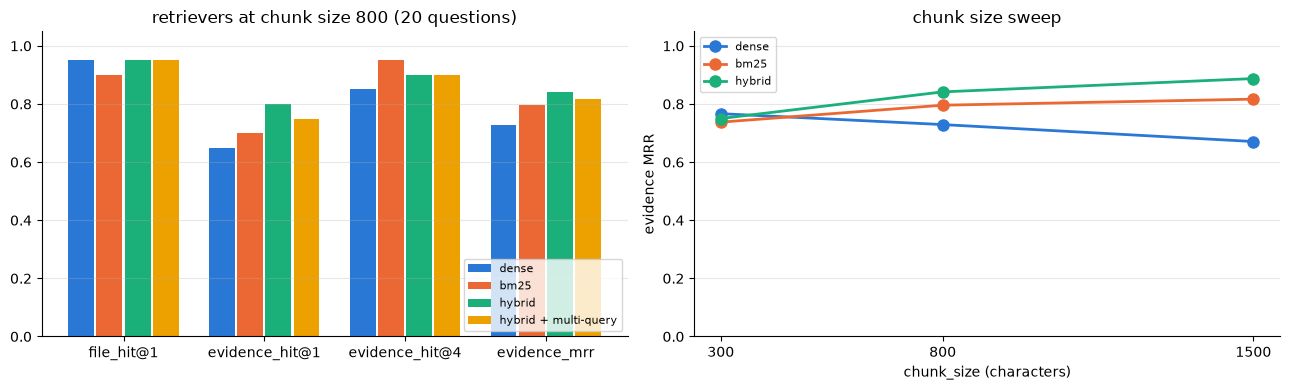

In [13]:
COLORS = {"dense": "#2a78d6", "bm25": "#eb6834", "hybrid": "#1baf7a", "hybrid + multi-query": "#eda100"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
names = list(retrieval_results)
metrics = ["file_hit@1", "evidence_hit@1", "evidence_hit@4", "evidence_mrr"]
x = np.arange(len(metrics)); w = 0.8 / len(names)
for i, n in enumerate(names):
    vals = [retrieval_results[n][m] for m in metrics]
    ax[0].bar(x + (i - (len(names) - 1) / 2) * w, vals, w * 0.92, color=COLORS[n], label=n)
ax[0].set_xticks(x); ax[0].set_xticklabels(metrics); ax[0].set_ylim(0, 1.05); ax[0].set_title("retrievers at chunk size 800 (20 questions)")
ax[0].legend(loc="lower right", fontsize=8)
for n in ("dense", "bm25", "hybrid"):
    ys = [sweep[(s, n)]["evidence_mrr"] for s in CHUNK_SIZES]
    ax[1].plot(CHUNK_SIZES, ys, marker="o", lw=2, ms=8, color=COLORS[n], label=n)
ax[1].set_xticks(CHUNK_SIZES); ax[1].set_xlabel("chunk_size (characters)"); ax[1].set_ylabel("evidence MRR"); ax[1].set_ylim(0, 1.05)
ax[1].set_title("chunk size sweep"); ax[1].legend(fontsize=8)
for a in ax:
    a.grid(axis="y", alpha=.3); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Reading the retrieval results.**
- At file level every retriever finds the right document in the top 4 (hit@4 = 1.00): the metric is saturated, which is exactly why we also score whether the chunk that actually *contains the evidence* was retrieved.
- At evidence level the differences appear. **Hybrid retrieval is the best at the top of the ranking** (evidence hit@1 0.80, MRR 0.84 vs 0.73 for dense alone), and **BM25 is surprisingly strong** (hit@4 0.95): our corpus is technical documentation full of exact identifiers (`--chunk-size`, `kv_lora_rank`, error messages) that lexical search matches and embeddings blur. Fusing both with RRF keeps the strengths of each.
- **Multi-query did not help** here (MRR 0.82, with one extra LLM call per question, ~15 s for 20 questions): paraphrasing pays off when users phrase questions very differently from the documents, not on precise technical questions.
- **Chunk size matters, and not in the same direction for every retriever**: dense retrieval gets worse with bigger chunks (MRR 0.77 → 0.67, the embedding of a long chunk averages too many topics), while BM25 and hybrid improve (up to 0.82 and 0.89). Two caveats: a bigger chunk contains the evidence string more easily, and every retrieved chunk costs prompt tokens. 800 characters is a reasonable middle ground for this corpus.

## 11. Evaluating generation with RAGAS

Good retrieval is necessary, not sufficient: the model can still ignore the context, add facts that are not there, or answer a different question. **RAGAS** scores generation with an LLM acting as a judge, broken into four questions:

| metric | question it answers | how it is computed | needs a reference? |
|---|---|---|---|
| **faithfulness** | is every claim in the answer supported by the retrieved context? | the judge splits the answer into atomic statements, then checks each one against the context (NLI); score = supported / total | no |
| **answer relevancy** | does the answer address the question? | the judge writes the question the answer seems to respond to; score = cosine similarity between that and the real question (embeddings) | no |
| **context precision** | are the relevant chunks ranked at the top? | the judge marks each retrieved chunk useful or not for the reference answer; score = average precision over the ranking | yes |
| **context recall** | does the context contain everything the reference answer needs? | the judge checks each sentence of the reference against the context | yes |

Faithfulness and answer relevancy can run on live traffic (no reference needed); context precision and recall need a labelled set like ours.

**The judge.** RAGAS 0.4 builds its metrics on structured output: `llm_factory(model, client=...)` wraps an OpenAI-style client with the Instructor library so every judge step returns a validated Pydantic object. (Its older `LangchainLLMWrapper` still exists but is deprecated in 0.4.) Ollama serves an OpenAI-compatible API at `/v1`, so local models act as the judge: `nomic-embed-text` for the embeddings and, as the grader, `qwen2.5:7b` when it is pulled (`config.judge_model()` falls back to the 3B generator otherwise). A judge should be stronger than the system it grades. The first version of this notebook let the 3B model grade its own answers, and the reading below shows what that did to the numbers.

Two practical details in the next cell:
- ragas 0.4.3 still imports a module (`langchain_community.chat_models.vertexai`) that langchain-community 0.4 removed. Until ragas fixes it, registering an empty stand-in module before the import is enough; we never use Vertex AI.
- We strip the `[n]` citation markers from the answers before scoring: the judge otherwise treats "[2]" as a claim that the context does not support, and faithfulness drops for a formatting reason.

In [14]:
import sys, types, asyncio
warnings.filterwarnings("ignore", message="IProgress not found")    # tqdm's notebook-widget warning, harmless
try:                                             # compatibility shim, see the note above
    import langchain_community.chat_models.vertexai  # noqa: F401
except ImportError:
    _stub = types.ModuleType("langchain_community.chat_models.vertexai")
    _stub.ChatVertexAI = type("ChatVertexAI", (), {})
    sys.modules[_stub.__name__] = _stub

from openai import AsyncOpenAI
from ragas.llms import llm_factory
from ragas.embeddings import OpenAIEmbeddings as RagasEmbeddings
from ragas.metrics.collections import Faithfulness, AnswerRelevancy, ContextPrecision, ContextRecall

judge_client = AsyncOpenAI(base_url=os.environ.get("OLLAMA_BASE_URL", "http://localhost:11434").rstrip("/") + "/v1", api_key="ollama",
                           timeout=180, max_retries=1)        # a stuck judge call becomes a missing score instead of a hung notebook
judge = llm_factory(info["judge_model"], client=judge_client, temperature=0)     # qwen2.5:7b if pulled: a judge stronger than the 3B it grades
judge_emb = RagasEmbeddings(client=judge_client, model=info["embedding_model"])

METRICS = {
    "faithfulness": Faithfulness(llm=judge),
    "answer_relevancy": AnswerRelevancy(llm=judge, embeddings=judge_emb, strictness=1),   # 1 generated question instead of 3, to save time
    "context_precision": ContextPrecision(llm=judge),
    "context_recall": ContextRecall(llm=judge),
}

def strip_citations(text):
    return re.sub(r"\s*\[\d+\](\[\d+\])*", "", text).strip()

async def ragas_scores(item, result, sem):
    ctx = [d.page_content for d in result["docs"]]
    ans = strip_citations(result["answer"])
    args = {"faithfulness": dict(user_input=item["question"], response=ans, retrieved_contexts=ctx),
            "answer_relevancy": dict(user_input=item["question"], response=ans),
            "context_precision": dict(user_input=item["question"], reference=item["answer"], retrieved_contexts=ctx),
            "context_recall": dict(user_input=item["question"], reference=item["answer"], retrieved_contexts=ctx)}
    async def one(name):
        async with sem:
            try:
                return name, (await METRICS[name].ascore(**args[name])).value
            except Exception as e:            # a small judge sometimes returns JSON that does not validate; count it as missing
                return name, float("nan")
    return dict(await asyncio.gather(*(one(n) for n in METRICS)))
print("generator:", info["chat_model"], "| judge:", info["judge_model"], "| embeddings:", info["embedding_model"])

generator: qwen2.5:3b | judge: qwen2.5:7b | embeddings: nomic-embed-text


### The RAGAS metrics as formulas, and the limits of an LLM judge

RAGAS (Es et al., 2023, *RAGAS: Automated Evaluation of Retrieval Augmented Generation*) decomposes "is this RAG answer good?" into checks that a judge model can perform reliably one at a time. Written out, for a question $q$, retrieved contexts $c_1, \dots, c_K$, an answer $a$ and a reference answer $g$:

- **Faithfulness.** The judge rewrites $a$ as a list of atomic claims $S(a)$ and decides, for each, whether it can be inferred from the contexts:
$$\text{faithfulness} = \frac{|\{s \in S(a) : s \text{ supported by } c_{1..K}\}|}{|S(a)|}$$
It measures *groundedness*, not correctness: an answer that faithfully repeats a wrong passage scores 1, and a correct answer from the model's own memory scores low. An answer with no claims ("I don't know") is an edge case that implementations treat differently.
- **Answer relevancy.** The judge generates $n$ questions $\hat q_i$ that the answer would be a response to, and the score is their mean embedding similarity to the real question:
$$\text{answer relevancy} = \frac{1}{n}\sum_{i=1}^{n}\cos\big(E(\hat q_i), E(q)\big)$$
Incomplete or evasive answers produce generated questions that drift from $q$. RAGAS also asks the judge whether the answer is *noncommittal* and sets the score to 0 if so, which is why a hedged but correct answer can score 0. With an embedding model the cosine rarely reaches 1 even for perfect answers, so the scale is relative.
- **Context precision.** For each retrieved chunk the judge decides whether it was useful for arriving at $g$ ($v_k \in \{0,1\}$), and the score is an average precision over the ranking:
$$\text{context precision@}K = \frac{\sum_{k=1}^{K} \text{precision@}k \cdot v_k}{\sum_{k=1}^{K} v_k}$$
It rewards rankings that put useful chunks first, like MRR in section 10, but with an LLM deciding relevance instead of an evidence string.
- **Context recall.** The judge splits the *reference* $g$ into claims and checks whether each can be attributed to the retrieved contexts:
$$\text{context recall} = \frac{|\{s \in S(g) : s \text{ attributable to } c_{1..K}\}|}{|S(g)|}$$
It is the generation-side counterpart of our evidence hit rate, and the only one of the four that tells you whether retrieval *missed* something the answer needed.

Together they localize a failure: low context recall points to retrieval, high recall with low faithfulness points to the generator, low answer relevancy with high faithfulness points to an answer that is grounded but does not address the question.

**LLM-as-judge: what is known about its biases.** Using a model to grade text was studied systematically by Zheng et al. (2023, *Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena*), who found strong judges agreeing with humans about as often as humans agree with each other, but also documented biases that apply to RAGAS too:

| bias | what happens | mitigation |
|---|---|---|
| position bias | in comparisons, the judge favours the first (or second) option | swap the order and average; RAGAS mostly scores single items, which reduces it |
| verbosity bias | longer answers are judged better or more complete | compare systems with similar answer lengths; read low-scoring short answers |
| self-preference | a judge rates text from its own model family higher | use a judge from a different family than the generator when possible |
| limited capability | a judge cannot verify what it cannot understand; weak judges misread tables, numbers and code | use a judge clearly stronger than the system under test |
| format failures | the judge's structured output does not validate and the score is missing | count missing scores and report them, as the code above does |
| run-to-run variance | the same item gets different scores across runs | fixed judge, temperature 0, repeated runs or confidence intervals |

The working rule follows from the table: an LLM judge is a **measurement instrument that must itself be validated**. Before trusting it, compare its verdicts with human labels on a sample (agreement rate or Cohen's kappa), keep the judge model and prompts fixed while comparing system versions, and read differences between systems more than absolute values. ARES (Saad-Falcon et al., 2023) goes one step further and fine-tunes small judges on synthetic data, then corrects their scores with a small human-labelled set through prediction-powered inference.

We compare two configurations that differ only in the retriever: **dense-only** and **hybrid**, both with 800-character chunks and k = 4. `chain.batch(..., max_concurrency=4)` sends the 20 questions in parallel; Ollama queues what the GPU cannot run at once.

In [15]:
CONFIGS = {"dense": make_rag_chain(dense), "hybrid": make_rag_chain(hybrid)}
questions = [it["question"] for it in EVAL]
outputs, timings = {}, {}
for name, chain in CONFIGS.items():
    t0 = time.time()
    outputs[name] = chain.batch(questions, config={"max_concurrency": 4})
    timings[name] = time.time() - t0
    print(f"{name:7s}: {len(questions)} answers in {timings[name]:.0f}s")
show(outputs["hybrid"][0])

dense  : 20 answers in 18s


hybrid : 20 answers in 15s
Q: What does Reciprocal Rank Fusion sum to combine several rankings, and what constant does it use?
A: RRF sums `1/(k + rank)` to combine several rankings, using `k = 60`. [1]
   [1] * module_reference.md  '`k1` controls term-frequency saturation and `b` length normalization. '
   [2]   glossary.md          '| Term | Meaning | Spanish docs |\n|---|---|---|\n| **RAG (Retrieval-Aug'
   [3]   notebooks_guide.md   '<a id="10"></a>\n## 10 · RAG\n`notebooks/04_applications/18_rag.ipynb` ·'
   [4]   module_reference.md  '- *Query expansion*: an LLM generates paraphrases, each one is retriev'


In [16]:
t0 = time.time()
sem = asyncio.Semaphore(4)                     # requests in flight; Ollama runs what it can in parallel and queues the rest
memo = {}                                      # when both configs retrieved the same chunks they gave the same answer: score it once

async def scored(item, out):
    key = (item["question"], out["answer"], tuple(d.page_content for d in out["docs"]))
    if key not in memo:
        memo[key] = asyncio.ensure_future(ragas_scores(item, out, sem))
    return await memo[key]

names = list(CONFIGS)
rows = await asyncio.gather(*(scored(it, out) for name in names for it, out in zip(EVAL, outputs[name])))
ragas_rows = {name: rows[i * len(EVAL):(i + 1) * len(EVAL)] for i, name in enumerate(names)}
print(f"RAGAS scoring: {time.time() - t0:.0f}s for {len(memo)} distinct (question, context, answer) triples "
      f"out of {len(names) * len(EVAL)}, {len(METRICS)} metrics each\n")

ragas_summary = {name: {m: float(np.nanmean([r[m] for r in rows])) for m in METRICS} for name, rows in ragas_rows.items()}
missing = {name: sum(np.isnan(r[m]) for r in rows for m in METRICS) for name, rows in ragas_rows.items()}
print(f"{'config':8s}" + "".join(f"{m:>19s}" for m in METRICS) + "   unscored")
for name, s in ragas_summary.items():
    print(f"{name:8s}" + "".join(f"{s[m]:19.2f}" for m in METRICS) + f"   {missing[name]:5d}")

RAGAS scoring: 1038s for 40 distinct (question, context, answer) triples out of 40, 4 metrics each

config         faithfulness   answer_relevancy  context_precision     context_recall   unscored
dense                  0.87               0.78               0.79               0.95       0
hybrid                 0.87               0.75               0.92               0.95       0


**How sure are we?** Twenty questions is a small sample, so before reading a difference we put an interval around it. The **bootstrap** resamples the 20 per-question scores with replacement 2,000 times and looks at how much the mean moves; the 2.5 % and 97.5 % quantiles give a 95 % interval. For the comparison we use the **paired** version: per question, hybrid minus dense, because both systems answered the same questions. If the interval of the difference excludes 0, the difference is unlikely to be noise. (`bootstrap_ci` and `paired_bootstrap_diff` are ten lines each in `llm_edu_suite/evaluation.py`.)

In [17]:
from llm_edu_suite.evaluation import bootstrap_ci, paired_bootstrap_diff
ragas_ci = {name: {m: bootstrap_ci([r[m] for r in rows]) for m in METRICS} for name, rows in ragas_rows.items()}
print(f"{'metric':18s} {'dense [95% CI]':>20s} {'hybrid [95% CI]':>20s} {'hybrid - dense [95% CI]':>26s}")
for m in METRICS:
    d, h = ragas_ci["dense"][m], ragas_ci["hybrid"][m]
    diff = paired_bootstrap_diff([r[m] for r in ragas_rows["dense"]], [r[m] for r in ragas_rows["hybrid"]])
    verdict = "hybrid better" if diff[1] > 0 else "dense better" if diff[2] < 0 else "no clear difference"
    print(f"{m:18s} {d[0]:5.2f} [{d[1]:.2f}, {d[2]:.2f}]   {h[0]:5.2f} [{h[1]:.2f}, {h[2]:.2f}]   {diff[0]:+.2f} [{diff[1]:+.2f}, {diff[2]:+.2f}]  {verdict}")

metric                   dense [95% CI]      hybrid [95% CI]    hybrid - dense [95% CI]
faithfulness        0.87 [0.74, 0.97]    0.87 [0.74, 0.96]   -0.00 [-0.16, +0.17]  no clear difference
answer_relevancy    0.78 [0.64, 0.89]    0.75 [0.60, 0.86]   -0.03 [-0.16, +0.10]  no clear difference
context_precision   0.79 [0.62, 0.92]    0.92 [0.80, 0.99]   +0.13 [+0.03, +0.25]  hybrid better
context_recall      0.95 [0.85, 1.00]    0.95 [0.85, 1.00]   +0.00 [-0.15, +0.15]  no clear difference


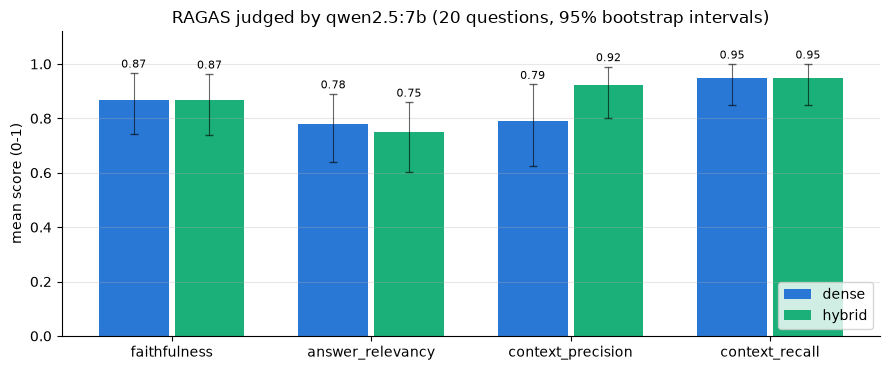

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(METRICS)); w = 0.38
for i, name in enumerate(CONFIGS):
    vals = [ragas_summary[name][m] for m in METRICS]
    err = np.array([[ragas_ci[name][m][0] - ragas_ci[name][m][1], ragas_ci[name][m][2] - ragas_ci[name][m][0]] for m in METRICS]).T
    bars = ax.bar(x + (i - 0.5) * w, vals, w * 0.92, color=COLORS[name], label=name, yerr=err, capsize=3, error_kw=dict(lw=0.8, alpha=0.6))
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(list(METRICS)); ax.set_ylim(0, 1.12); ax.set_ylabel("mean score (0-1)")
ax.set_title(f"RAGAS judged by {info['judge_model']} (20 questions, 95% bootstrap intervals)"); ax.legend(loc="lower right")
ax.grid(axis="y", alpha=.3); ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

### Looking at individual questions

Averages hide the interesting part. Below, every question with its evidence rank (did retrieval find it?) next to the RAGAS scores of the hybrid configuration. Read the low rows: is the failure in retrieval (no evidence in the top 4), in generation (evidence there, answer unfaithful), or in the judge?

In [19]:
print(f"{'question':58s} {'ev.rank':>7s} {'faith':>6s} {'relev':>6s} {'c.prec':>6s} {'c.rec':>6s}")
for it, r, rank in zip(EVAL, ragas_rows["hybrid"], evidence_ranks["hybrid"]):
    print(f"{it['question'][:57]:58s} {str(rank or '-'):>7s} " + " ".join(f"{r[m]:6.2f}" for m in METRICS))
worst = min(range(len(EVAL)), key=lambda i: np.nan_to_num(ragas_rows["hybrid"][i]["faithfulness"], nan=1.0))
print("\nlowest faithfulness (hybrid):")
show(outputs["hybrid"][worst]); print("reference:", EVAL[worst]["answer"])

question                                                   ev.rank  faith  relev c.prec  c.rec
What does Reciprocal Rank Fusion sum to combine several r        1   1.00   0.77   1.00   1.00
How does RMSNorm differ from LayerNorm?                          2   0.71   0.98   1.00   1.00
What is the difference between head sampling and tail sam        1   1.00   0.77   1.00   1.00
What is tool poisoning in MCP?                                   1   0.83   0.84   0.81   1.00
What is the minimum Python version required by the projec        1   1.00   1.00   1.00   1.00
What causes the error 'ImportError: numpy.core.multiarray        1   0.67   0.91   1.00   1.00
What can you do if PowerShell blocks Activate.ps1?               1   0.50   0.52   1.00   1.00
Which PyTorch build does the automatic setup script insta        1   1.00   0.78   0.81   1.00
What are the default chunk size and overlap in rag_demo.p        3   1.00   0.86   0.83   1.00
Why must an MCP server that uses the stdio transpo

**Reading the RAGAS results — and the judge.**
- With the 7B judge both configurations look good: faithfulness 0.87, context recall 0.95, answer relevancy 0.75 to 0.78. With 20 questions the intervals are wide (about ±0.1 to 0.15), and the paired bootstrap finds **one** clear difference: **context precision, 0.79 → 0.92 (+0.13, 95 % CI [+0.03, +0.25])**. Hybrid retrieval puts the useful chunks higher, which is what our label-based MRR said too. Faithfulness, relevancy and recall show no clear difference: once the right passage is somewhere in the top 4, the 3B generator answers about equally well from either list.
- **The judge mattered more than the system.** When the 3B model graded its own answers (the first version of this notebook), it reported faithfulness 0.38 → 0.54 and answer relevancy 0.44 → 0.30 for dense → hybrid, and its per-question scores gave relevancy 0 to correct answers. Graded by the 7B, the same kind of answers score 0.87 on faithfulness and those "differences" vanish inside the intervals. A weak judge does not only add noise; it can invent effects. **Validate the judge** before trusting a comparison: a stronger model than the one judged, a few dozen human spot checks, and the same judge kept fixed while you compare system versions.
- The low rows of the table separate the three ways a RAG answer fails. "Where does mini_llm.py save its checkpoint?" is a **retrieval** failure: no evidence in the top 4, so context precision and recall are 0. "What copy accuracy do the dense GQA and sliding-window models reach?" is a **generation** failure: the evidence was ranked first and both context metrics are 1.00, yet the 3B model answered "I don't know", so faithfulness and relevancy are 0. The DPO + NLL question shows a **label** problem: our evidence check finds no labelled passage in the top 4, but the judge finds the fact in the context (recall 1.00). Gold labels need checking too.
- Cost: a stronger judge is slower. Scoring 40 answers × 4 metrics took 1038 s (about 17 minutes) with the 7B, against about 7 minutes with the 3B, and it is most of this notebook's runtime. Evaluation is a real budget line: run it on a fixed, small, representative set on every change, not on everything.

## Takeaways

- A RAG system is a **retriever plus a generator, and you evaluate them separately**. Retrieval metrics need only labels and run in seconds; RAGAS needs an LLM judge and runs in minutes.
- **Hybrid retrieval (BM25 + dense with RRF) is the default to beat.** Technical documentation is full of exact strings that embeddings blur.
- **Chunk size is a hyperparameter**: measure it on your own questions instead of copying a default.
- **Query rewriting is not free**: an extra LLM call per question, and it only pays off when queries and documents use different words.
- **LLM judges are models too.** A 3B judge is noisy and sometimes fails to return valid JSON; use a stronger judge than the system under test, spot-check its verdicts by hand, and compare configurations on the same judge rather than reading absolute numbers.

**Failure modes and fixes**

| symptom | likely cause | fix |
|---|---|---|
| the answer is in the docs but not retrieved | chunks too large or too small, wording mismatch | measure chunk sizes, hybrid search, multi-query / HyDE |
| the right chunk is retrieved but the model ignores it | too much context, weak instructions, small model | fewer and better chunks, a reranker, "answer only from context", require citations |
| the question needs facts from several places | single-shot retrieval | iterative or agentic retrieval (notebook 25), parent-document retrieval |
| wrong on names, codes, versions | dense-only retrieval | add BM25 |
| slow | big context, brute-force index | smaller k, ANN index (HNSW), cache embeddings |

## Results

| question | measured | lesson |
|---|---|---|
| does retrieval find the right file? | file hit@4 1.00 for every retriever (chunks of 800 characters) | a saturated metric; score the evidence chunk instead |
| which retriever ranks the evidence best? | evidence hit@1: dense 0.65, BM25 0.70, hybrid 0.80; MRR 0.73 / 0.80 / 0.84 | hybrid (BM25 + dense with RRF) is the default to beat |
| does multi-query help? | MRR 0.82 vs 0.84 for plain hybrid, plus 15 s of LLM calls for 20 questions | an extra call per question, no gain on precise questions |
| does chunk size matter? | dense MRR 0.77 → 0.67 from 300 to 1500 characters; hybrid 0.75 → 0.89 | tune it on your own questions |
| RAGAS, dense vs hybrid (7B judge) | context precision 0.79 → 0.92 (+0.13, 95 % CI [+0.03, +0.25]); faithfulness 0.87 and context recall 0.95 for both | only precision differs clearly at n = 20 |
| what does the judge cost? | 1038 s to score 40 answers × 4 metrics | evaluation is a real budget line |

## Limitations

- **Small evaluation set.** 20 questions over one corpus (five Markdown files of this repository's docs). Intervals are about ±0.1 to 0.15, so only large differences are real.
- **One generator, one judge, same family.** `qwen2.5:3b` answers and `qwen2.5:7b` judges; a judge from the same family may favour its relative, and we did not validate it against human labels, only by reading the low rows.
- **Labels can be wrong.** The evidence strings were written by hand, and one question (DPO + NLL) showed a label miss.
- **No reranker, no vector database, no access control.** The index is an in-memory FAISS store; rerankers are measured in notebook 17.
- **One execution.** Judge verdicts on borderline answers can flip between runs.

## In production

**The architecture.**
- The same structure scales up: a hosted or larger embedding model, a vector database (pgvector, Qdrant, Weaviate, or Elasticsearch / OpenSearch with hybrid search built in), a cross-encoder reranker on the top 20-50 candidates (notebook 17), and metadata filters that enforce who may see which document.
- `scripts/rag_demo.py` packages this notebook's pipeline as a command-line tool.

**Today's practice (late 2026).**
- Long-context models have not replaced retrieval: retrieving is cheaper, faster, and gives citations you can check. Many systems retrieve a little, then read bigger parent chunks or whole documents.
- Agentic retrieval, where the model decides when and what to search over several steps (notebook 25), is common for questions that need several sources.
- Chunks are often enriched before embedding (a short LLM-written context per chunk), and stable context is reused with prompt caching.

**Evaluation.** RAGAS, DeepEval, LangSmith or Phoenix (notebooks 28 and 29), on a fixed set built from real user questions, run on every change to chunking, embeddings, prompt or model.

**Failure modes.**
- A stale index: documents changed, embeddings did not.
- Changing the embedding model without re-indexing everything.
- Retrieving documents the user is not allowed to see.
- Prompt injection inside retrieved documents (notebooks 19 and 30).
- Chunking that splits tables and code blocks.
- Trusting a judge nobody validated.

**Next:** `19_modern_llm_applications.ipynb`: extraction, classification, summarization, caching and prompt-injection defense.